# 03 Lineage cutoff

Chooses the SNP cutoff that defines lineages (families) for the lineage split.

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sys

src_dir = Path("../src").resolve()
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

import data
ANTIBIOTICS = data.ANTIBIOTICS
X, labels, year, clusters = data.load_data()

main_antibiotics = ["CIP", "GEN", "CXM"]

In [3]:
clusters.head()

,cutoff_2,cutoff_3,cutoff_4,cutoff_5,cutoff_6,cutoff_7,cutoff_8,cutoff_9,cutoff_10,cutoff_11,...,cutoff_25459,cutoff_25654,cutoff_25772,cutoff_25979,cutoff_26792,cutoff_27119,cutoff_27236,cutoff_27248,cutoff_27690,cutoff_45092
11657_5#1,Cl11,Cl11,Cl11,Cl11,Cl11,Cl11,Cl11,Cl11,Cl11,Cl11,...,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1
11657_5#10,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,...,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1
11657_5#11,Cl2,Cl2,Cl2,Cl2,Cl2,Cl2,Cl2,Cl2,Cl2,Cl2,...,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1
11657_5#12,Cl3,Cl3,Cl3,Cl3,Cl3,Cl3,Cl3,Cl3,Cl3,Cl3,...,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1
11657_5#13,Cl4,Cl4,Cl4,Cl4,Cl4,Cl4,Cl4,Cl4,Cl4,Cl4,...,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1,Cl1


Each column groups strains into families at one SNP cutoff. Small cutoffs give many small families, large cutoffs give a few big ones.

## Families at each cutoff

In [6]:
rows = []
for column in clusters.columns:
    sizes = clusters[column].value_counts()
    rows.append({
        "cutoff": int(column.split("_")[1]),
        "column": column,
        "n_clusters": len(sizes),
        "largest_pct": round(sizes.max() / len(clusters) * 100, 1),
        "singleton_pct": round((sizes == 1).sum() / len(clusters) * 100, 1),
    })

cutoff_summary = pd.DataFrame(rows).set_index("cutoff")
cutoff_summary

,column,n_clusters,largest_pct,singleton_pct
cutoff,,,,
2,cutoff_2,1933,0.1,99.7
3,cutoff_3,1931,0.1,99.5
4,cutoff_4,1926,0.2,99.0
5,cutoff_5,1921,0.2,98.6
6,cutoff_6,1920,0.2,98.6
...,...,...,...,...
27119,cutoff_27119,6,99.6,0.2
27236,cutoff_27236,5,99.8,0.2
27248,cutoff_27248,4,99.8,0.2


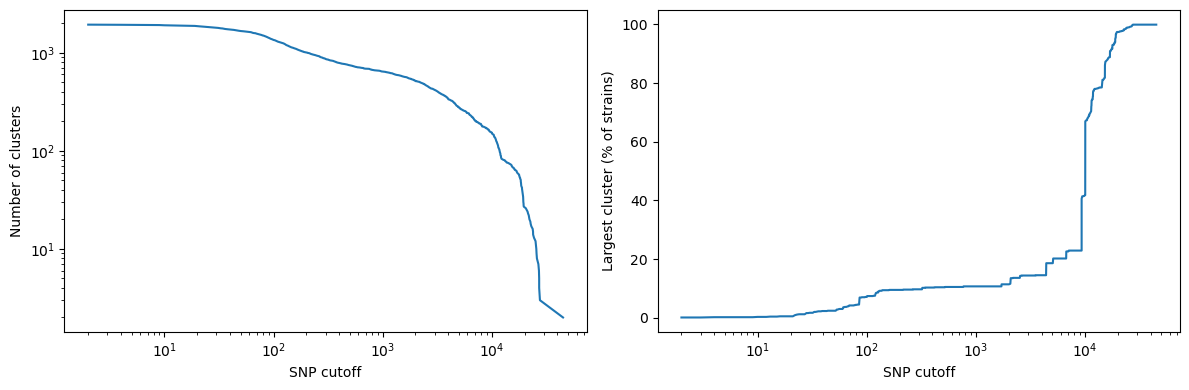

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cutoff_summary["n_clusters"].plot(ax=axes[0], logx=True, logy=True)
axes[0].set_xlabel("SNP cutoff")
axes[0].set_ylabel("Number of clusters")

cutoff_summary["largest_pct"].plot(ax=axes[1], logx=True)
axes[1].set_xlabel("SNP cutoff")
axes[1].set_ylabel("Largest cluster (% of strains)")
plt.tight_layout()
plt.show()

As the cutoff grows, the number of families falls and the biggest family grows.

## Candidate cutoffs

In [10]:
candidates = cutoff_summary[
    (cutoff_summary["n_clusters"] >= 50) &
    (cutoff_summary["largest_pct"] <= 20) &
    (cutoff_summary["singleton_pct"] < 50)
]
candidates

,column,n_clusters,largest_pct,singleton_pct
cutoff,,,,
141,cutoff_141,1151,9.4,49.5
142,cutoff_142,1145,9.4,49.2
143,cutoff_143,1143,9.4,49.0
144,cutoff_144,1141,9.4,48.8
145,cutoff_145,1139,9.4,48.7
...,...,...,...,...
4986,cutoff_4986,278,18.6,9.0
5004,cutoff_5004,277,18.6,9.0
5052,cutoff_5052,276,18.6,9.0


In [11]:
print("Number of candidate cutoffs:", len(candidates))
print("Smallest:", candidates.index.min(), "  Largest:", candidates.index.max())

Number of candidate cutoffs: 664
Smallest: 141   Largest: 5077


664 of the 1071 cutoffs meet the three rules, from cutoff 141 to 5077.

## Fold check

In [14]:
positions = np.linspace(0, len(candidates) - 1, 5).round().astype(int)
chosen_cutoffs = candidates.index[positions]
chosen_cutoffs

Index([141, 362, 1168, 2628, 5077], dtype='int64', name='cutoff')

In [15]:
from sklearn.model_selection import StratifiedGroupKFold

def resistant_per_fold(column, antibiotic):
    y = labels[antibiotic].dropna()
    groups = clusters.loc[y.index, column]
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
    counts = []
    for train_idx, test_idx in cv.split(np.zeros(len(y)), y, groups):
        counts.append((y.iloc[test_idx] == "R").sum())
    return counts

In [16]:
first_column = candidates.loc[chosen_cutoffs[0], "column"]
resistant_per_fold(first_column, "GEN")

[42, 38, 55, 38, 111]

Test on one cutoff: every GEN test fold has about 57 resistant strains.

In [18]:
rows = []
for cutoff in chosen_cutoffs:
    column = candidates.loc[cutoff, "column"]
    row = {
        "n_clusters": candidates.loc[cutoff, "n_clusters"],
        "largest_pct": candidates.loc[cutoff, "largest_pct"],
        "singleton_pct": candidates.loc[cutoff, "singleton_pct"],
    }
    for antibiotic in main_antibiotics:
        row[f"min_R_{antibiotic}"] = min(resistant_per_fold(column, antibiotic))
    rows.append(row)

fold_check = pd.DataFrame(rows, index=chosen_cutoffs)
fold_check

,n_clusters,largest_pct,singleton_pct,min_R_CIP,min_R_GEN,min_R_CXM
cutoff,,,,,,
141,1151,9.4,49.5,42,38,78
362,817,10.3,31.8,45,35,71
1168,623,10.7,22.2,43,37,53
2628,448,14.3,15.3,34,33,42
5077,273,18.6,8.9,27,21,54


## Summary

A good cutoff needs:
- at least 50 families
- no family bigger than 20% of strains
- most strains (over 50%) with at least one relative

5 cutoffs spread evenly across the 664 that meet these rules were checked. All of them give every test fold more than 20 resistant strains for CIP, GEN and CXM.

**1168** was chosen because it is in the middle of these 5:
- 623 families
- the biggest family has 10.7% of strains
- 78% of strains have at least one relative
- every test fold has at least 37 resistant strains